# Credit card fraud detection

The dataset is about 285,000 card transactions made by European cardholders over two days in September 2013. Only a tiny fraction of them are fraud.
Features `V1` to `V28` are PCA components (the original features were hidden for privacy), plus `Time`, `Amount` and the label `Class` (1 = fraud).

In [1]:
# import packages (tensorflow first, importing it after pandas made training hang on my Mac)
import tensorflow as tf
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, precision_recall_curve, confusion_matrix)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# seeds so the results can be repeated
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

In [3]:
# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

df = pd.read_csv(path + "/creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Shape: (284807, 31)
Missing values: 0


In [5]:
counts = df['Class'].value_counts()
print(counts)
print("Fraud percentage:", round(counts[1] / len(df) * 100, 3), "%")

Class
0    284315
1       492
Name: count, dtype: int64
Fraud percentage: 0.173 %


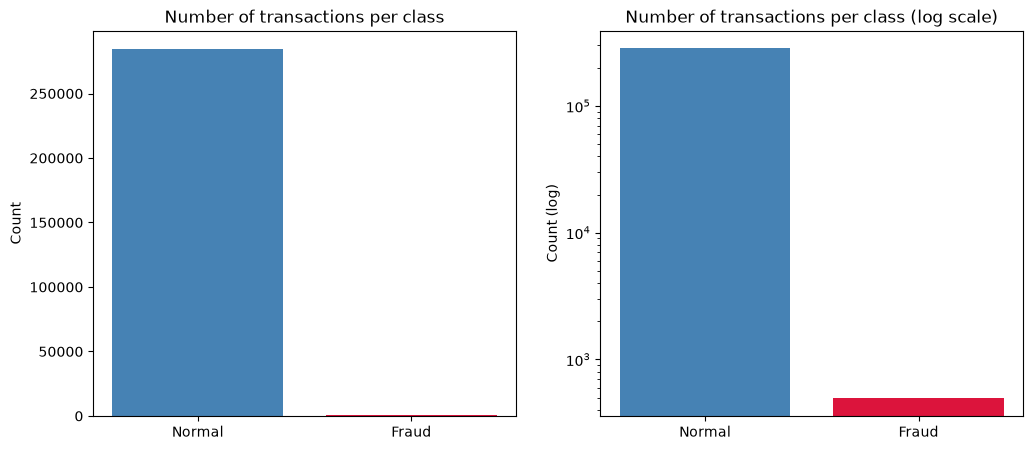

In [6]:
# plot the class imbalance, normal scale and log scale
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Normal', 'Fraud'], counts.values, color=['steelblue', 'crimson'])
axes[0].set_title('Number of transactions per class')
axes[0].set_ylabel('Count')

axes[1].bar(['Normal', 'Fraud'], counts.values, color=['steelblue', 'crimson'])
axes[1].set_yscale('log')
axes[1].set_title('Number of transactions per class (log scale)')
axes[1].set_ylabel('Count (log)')

plt.show()

### Why accuracy is misleading here

Fraud is about 0.17% of the data. A "model" that just says every transaction is normal would get almost perfect accuracy while catching zero fraud. So accuracy tells us nearly nothing.
The cell below shows this. Instead I will use precision (of the transactions we flag, how many are really fraud), recall (of all the fraud, how much we catch), F1 and the area under the precision-recall curve (PR-AUC).

In [7]:
# a "model" that always predicts normal
always_normal = np.zeros(len(df))
print("Accuracy of always predicting normal:", accuracy_score(df['Class'], always_normal))
print("Recall of always predicting normal:", recall_score(df['Class'], always_normal))

Accuracy of always predicting normal: 0.9982725143693799
Recall of always predicting normal: 0.0


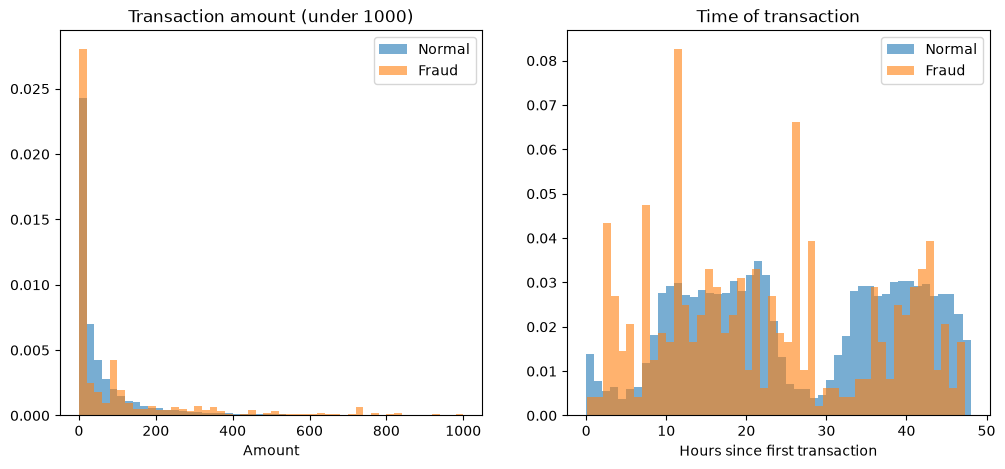

In [8]:
# compare Amount and Time for normal and fraud transactions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(df[df['Class'] == 0]['Amount'], bins=50, alpha=0.6, density=True, label='Normal', range=(0, 1000))
axes[0].hist(df[df['Class'] == 1]['Amount'], bins=50, alpha=0.6, density=True, label='Fraud', range=(0, 1000))
axes[0].set_title('Transaction amount (under 1000)')
axes[0].set_xlabel('Amount')
axes[0].legend()

axes[1].hist(df[df['Class'] == 0]['Time'] / 3600, bins=48, alpha=0.6, density=True, label='Normal')
axes[1].hist(df[df['Class'] == 1]['Time'] / 3600, bins=48, alpha=0.6, density=True, label='Fraud')
axes[1].set_title('Time of transaction')
axes[1].set_xlabel('Hours since first transaction')
axes[1].legend()

plt.show()

In [9]:
print(df[['Time', 'Amount']].describe())

                Time         Amount
count  284807.000000  284807.000000
mean    94813.859575      88.349619
std     47488.145955     250.120109
min         0.000000       0.000000
25%     54201.500000       5.600000
50%     84692.000000      22.000000
75%    139320.500000      77.165000
max    172792.000000   25691.160000


### Split and scale

`V1` to `V28` are already scaled by the PCA, but `Time` and `Amount` are not (Amount goes up to about 25,000).
I split first (60% train, 20% validation, 20% test, stratified so every split keeps the same fraud rate) and then fit the scaler on the training set only, so no information from the validation or test sets leaks in.

In [10]:
X = df.drop('Class', axis=1)
y = df['Class']

# 60 / 20 / 20 split, stratified on the class
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

print("Train:", X_train.shape, "fraud:", y_train.sum())
print("Val:  ", X_val.shape, "fraud:", y_val.sum())
print("Test: ", X_test.shape, "fraud:", y_test.sum())

Train: (170884, 30) fraud: 295
Val:   (56961, 30) fraud: 98
Test:  (56962, 30) fraud: 99


In [11]:
# scale Time and Amount, fitted on the training set only
scaler = StandardScaler()
X_train[['Time', 'Amount']] = scaler.fit_transform(X_train[['Time', 'Amount']])
X_val[['Time', 'Amount']] = scaler.transform(X_val[['Time', 'Amount']])
X_test[['Time', 'Amount']] = scaler.transform(X_test[['Time', 'Amount']])

X_train = X_train.values.astype('float32')
X_val = X_val.values.astype('float32')
X_test = X_test.values.astype('float32')
y_train = y_train.values
y_val = y_val.values
y_test = y_test.values